# Urban Heat Analysis in Atlanta: EDA (Boxplot and Scatterplot)
248 City of Atlanta neighborhoods | LST: Landsat 9, June 26, 2024 | Canopy and land cover: NLCD 2024

In [15]:
import glob, numpy as np, geopandas as gpd, rasterio, matplotlib.pyplot as plt, seaborn as sns
from rasterio.merge import merge
from rasterstats import zonal_stats

hoods = gpd.read_file("data/boundaries/atlanta_neighborhoods.geojson")


st_files = sorted(glob.glob("data/landsat/*20240626*ST_B10.TIF"))
with rasterio.open(st_files[0]) as src: crs = src.crs
box = tuple(hoods.to_crs(crs).total_bounds)
st, transform = merge(st_files, bounds=box)
qa, _ = merge(sorted(glob.glob("data/landsat/*20240626*QA_PIXEL.TIF")), bounds=box)
lst = (st[0] * 0.00341802 + 149 - 273.15) * 9 / 5 + 32
lst[(st[0] == 0) | ((qa[0] & 0b10011110) != 0)] = np.nan
hoods["lst_f"] = [z["mean"] for z in zonal_stats(hoods.to_crs(crs), lst, affine=transform, nodata=np.nan, stats="mean")]

# Tree canopy %: mean canopy per neighborhood
def zonal(path, **kw):
    with rasterio.open(path) as src: return zonal_stats(hoods.to_crs(src.crs), path, **kw)
hoods["canopy_pct"] = [z["mean"] for z in zonal("data/nlcd/tree_canopy_2024.tiff", stats="mean", nodata=255)]

# Developed land %: share of non-water pixels in NLCD classes 22-24 (low, medium, high intensity).
# Class 21 (Developed Open Space: lawns, parks) is left out; with it, most neighborhoods score ~100%.
dev = zonal("data/nlcd/annual_nlcd_landcover_2024.tiff", categorical=True, nodata=250)
hoods["developed_pct"] = [100 * sum(z.get(c, 0) for c in (22, 23, 24)) / (sum(z.values()) - z.get(11, 0)) for z in dev]

## Box plots: spread and outliers

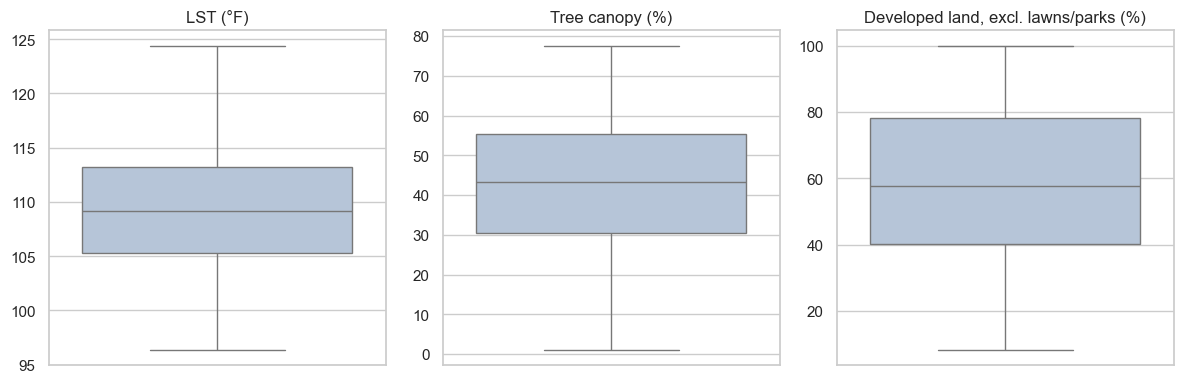

In [16]:
labels = {"lst_f": "LST (°F)", "canopy_pct": "Tree canopy (%)", "developed_pct": "Developed land, excl. lawns/parks (%)"}
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (col, label) in zip(axes, labels.items()):
    sns.boxplot(y=hoods[col], ax=ax, color="lightsteelblue").set(title=label, ylabel="")
plt.tight_layout()

## Scatter plots: LST vs canopy and developed land

Tree canopy (%) slope (deg F per 1 pt): -0.324
Canopy vs developed r: -0.92
Developed land, excl. lawns/parks (%) slope (deg F per 1 pt): 0.22
Canopy vs developed r: -0.92


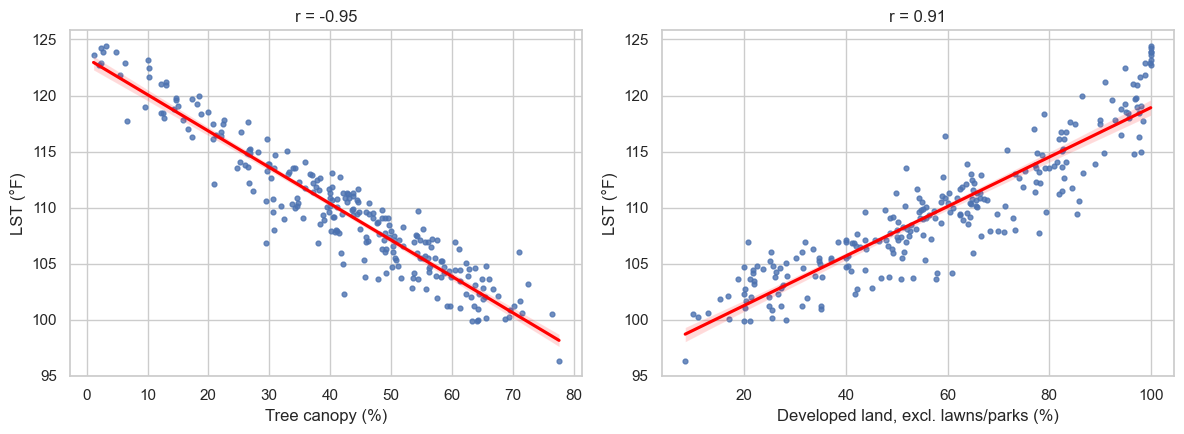

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, x in zip(axes, ["canopy_pct", "developed_pct"]):
    sns.regplot(x=hoods[x], y=hoods["lst_f"], ax=ax, scatter_kws={"s": 12}, line_kws={"color": "red"})
    ax.set(xlabel=labels[x], ylabel=labels["lst_f"], title=f"r = {hoods[x].corr(hoods['lst_f']):.2f}")
    print(labels[x], "slope (deg F per 1 pt):", round(np.polyfit(hoods[x], hoods["lst_f"], 1)[0], 3))
    print("Canopy vs developed r:", round(hoods["canopy_pct"].corr(hoods["developed_pct"]), 2))
plt.tight_layout()

## Initial findings

**Box plots (spread across 248 neighborhoods)**
- **LST:** middle neighborhood about 109°F; half of all neighborhoods fall between 105°F and 113°F. Full range 96°F to 124°F, a 28°F gap on the same summer morning.
- **Tree canopy:** middle neighborhood about 43%; half fall between 31% and 55%. Ranges from about 1% (Downtown, Oakland) to 78% (Butner/Tell), so tree cover is very uneven across the city.
- **Developed land (excl. lawns/parks):** middle neighborhood about 58%; half fall between 40% and 78%.
- **No outliers in any of the three:** no neighborhood is unusually far from the rest, so no data needs to be removed.

**Scatter plots (relationships with LST)**
- **More trees, cooler neighborhoods (r = -0.95):** about 3.2°F cooler for every 10 percentage points of tree canopy. The hottest areas (Castleberry Hill, Buckhead Village, Atlantic Station) have under 5% canopy.
- **More development, hotter neighborhoods (r = 0.91):** about 2.2°F hotter for every 10 percentage points of developed land.
- **Canopy and development are closely linked (r = -0.92):** built-up areas have fewer trees, so the two features overlap heavily.